# 6BUIS017W CWK1 – S&P 500 risk-return and trading activity clustering
* Study period: 1 Jan 2021 to 1 Jan 2025 (end exclusive). Source: yfinance. Benchmark: ^GSPC.
* Raw data is saved to `data/` and reused on re-runs (cached dataset if live access fails).

In [2]:
# Setup
!pip -q install yfinance lxml

import os, json, platform
from datetime import datetime, timezone
import pandas as pd, numpy as np
import yfinance as yf
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
import scipy, sklearn
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

START, END, BENCH = '2021-01-01', '2025-01-01', '^GSPC'
SEED = 42
DATA, FIGS = 'data', 'figures'
os.makedirs(DATA, exist_ok=True); os.makedirs(FIGS, exist_ok=True)
sns.set_theme(style='whitegrid')

versions = {p.__name__: p.__version__ for p in (pd, np, yf, matplotlib, sns, scipy, sklearn)}
versions['python'] = platform.python_version()
print(versions)

{'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'python': '3.13.18'}


## 1.1 Ticker selection and data acquisition

In [3]:
# 1.1 Ticker list (saved with retrieval date)
tick_file, meta_file = f'{DATA}/sp500_constituents.csv', f'{DATA}/metadata.json'
if os.path.exists(tick_file):
    sp500_df, meta = pd.read_csv(tick_file), json.load(open(meta_file))
else:
    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    sp500_df = pd.read_html(url, storage_options={'User-Agent': 'Mozilla/5.0'})[0]
    sp500_df['Yahoo_Ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
    sp500_df.to_csv(tick_file, index=False)
    meta = {'ticker_source': url, 'ticker_retrieved_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
            'start': START, 'end_exclusive': END, 'price_source': 'yfinance', 'benchmark': BENCH}
meta['versions'] = versions
json.dump(meta, open(meta_file, 'w'), indent=2)

tickers = sp500_df['Yahoo_Ticker'].tolist()
names = sp500_df.set_index('Yahoo_Ticker')[['Security', 'GICS Sector']]
print('Tickers:', len(tickers), '| retrieved:', meta['ticker_retrieved_utc'])

Tickers: 503 | retrieved: 2026-11-19T11:21:38+00:00


In [4]:
# 1.1 Daily prices, adjusted prices, volume and splits for shares + benchmark
# Saved as a portable long-format CSV snapshot. If live access fails, set CACHE_PATH to a saved snapshot.
CACHE_PATH = None   # e.g. '/content/market_data_2021-01-01_2025-01-01.csv.gz'
snap_file = f'{DATA}/market_data_{START}_{END}.csv.gz'

if CACHE_PATH or os.path.exists(snap_file):
    raw_long = pd.read_csv(CACHE_PATH or snap_file, parse_dates=['Date'])
    raw = raw_long.set_index(['Date', 'Ticker']).unstack('Ticker')
    print('Loaded snapshot:', CACHE_PATH or snap_file)
else:
    raw = yf.download(tickers + [BENCH], start=START, end=END, auto_adjust=False, actions=True, threads=False)
    raw_long = raw.stack(level=1, future_stack=True).rename_axis(['Date', 'Ticker']).reset_index()
    raw_long.to_csv(snap_file, index=False, compression='gzip')
    meta['price_downloaded_utc'] = datetime.now(timezone.utc).isoformat(timespec='seconds')
    json.dump(meta, open(meta_file, 'w'), indent=2)

adj, close, volume = raw['Adj Close'], raw['Close'], raw['Volume']
splits = raw['Stock Splits'] if 'Stock Splits' in raw else adj * 0
for f in (adj, close, volume, splits):
    f.index = pd.to_datetime(f.index).tz_localize(None)
print('Dates:', adj.index.min().date(), 'to', adj.index.max().date(), '| columns:', adj.shape[1])

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'SNDK', 'HONA', 'VYLR', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Dates: 2021-01-04 to 2024-12-31 | columns: 504


## 1.2 Data validation and alignment
Nothing is filled. A share is **excluded** if it has: no data, a history that doesn't cover the full period, any missing Adj Close/Close/Volume, any price ≤ 0, or any volume ≤ 0. The trading calendar is the benchmark's trading days.

In [5]:
# 1.2 Validation checks and exclusion log
assert not adj.index.duplicated().any(), 'Duplicate dates'
cal = adj.index[adj[BENCH].notna()]
first, last = cal.min(), cal.max()

rows = []
for t in tickers:
    a, c, v = (f.get(t, pd.Series(dtype=float)).reindex(cal) for f in (adj, close, volume))
    reasons = []
    if a.notna().sum() == 0:
        reasons.append('no data')
    else:
        if a.first_valid_index() > first or a.last_valid_index() < last: reasons.append('incomplete history')
        if a.isna().any() or c.isna().any() or v.isna().any():      reasons.append('missing values')
        if (a <= 0).any() or (c <= 0).any():                        reasons.append('non-positive price')
        if (v <= 0).any():                                          reasons.append('volume error')
    rows.append({'Ticker': t, 'First_date': a.first_valid_index(), 'Last_date': a.last_valid_index(),
                 'Reason': '; '.join(reasons)})

log = pd.DataFrame(rows).set_index('Ticker').join(names)
log.to_csv(f'{DATA}/validation_log.csv')
valid = log.index[log['Reason'] == ''].tolist()
print('Duplicate dates: 0 | Trading days:', len(cal))
print('Retained:', len(valid), '| Excluded:', len(tickers) - len(valid))
log[log['Reason'] != '']

Duplicate dates: 0 | Trading days: 1005
Retained: 486 | Excluded: 17


,First_date,Last_date,Reason,Security,GICS Sector
Ticker,,,,,
APP,2021-04-15,2024-12-31,incomplete history; missing values,AppLovin,Communication Services
COIN,2021-04-14,2024-12-31,incomplete history; missing values,Coinbase,Financials
CEG,2022-01-19,2024-12-31,incomplete history; missing values,Constellation Energy,Utilities
EXE,2021-02-10,2024-12-31,incomplete history; missing values,Expand Energy,Energy
FDXF,NaT,NaT,no data,FedEx Freight,Industrials
FERG,2021-01-04,2024-12-31,volume error,Ferguson Enterprises,Industrials
GEHC,2022-12-15,2024-12-31,incomplete history; missing values,GE HealthCare,Health Care
GEV,2024-03-27,2024-12-31,incomplete history; missing values,GE Vernova,Industrials
HONA,NaT,NaT,no data,Honeywell Aerospace,Industrials


In [6]:
# 1.2 Corporate actions: splits in the period, and any >50% daily move NOT on a split day
sp = splits[valid].reindex(cal).fillna(0)
split_list = sp.stack().loc[lambda x: x > 0]
print('Splits among retained shares:'); display(split_list.rename('Ratio').to_frame())

big = (close[valid].reindex(cal).pct_change(fill_method=None).abs() > 0.5) & (sp == 0)
print('Unexplained >50% daily moves:', big.stack().loc[lambda x: x].index.tolist())
# Yahoo 'Close' and 'Volume' are split-adjusted; 'Adj Close' also adjusts for dividends.

Splits among retained shares:


,,Ratio
Date,Ticker,
2021-03-05,APH,2.000
2021-04-01,SHW,3.000
2021-06-03,MRK,1.048
2021-06-28,CSGP,10.000
2021-06-29,CSX,3.000
...,...,...
2024-10-03,LRCX,10.000
2024-12-04,ANET,4.000
2024-12-13,ETR,2.000


Unexplained >50% daily moves: [(Timestamp('2023-06-08 00:00:00'), 'CVNA'), (Timestamp('2024-04-11 00:00:00'), 'GL'), (Timestamp('2024-11-15 00:00:00'), 'BE')]


**Survivorship bias:** today's constituent list is applied to 2021–2024, so firms removed from the index since 2021 are missing and later additions (often strong performers) are included. Returns are likely biased upwards.

## 1.3 Weekly return and weekly beta
Friday-ending weeks, last available Adj Close in each week. Incomplete first/final calendar weeks are dropped; holiday-shortened weeks are kept.

In [7]:
# 1.3 Weekly prices and returns (shares and benchmark on the same week labels)
daily = adj[valid + [BENCH]].reindex(cal)
wpx = daily.resample('W-FRI').last()
days_in_week = daily[BENCH].resample('W-FRI').count()

complete = ((wpx.index - pd.Timedelta(days=6)) >= pd.Timestamp(START)) & \
           (wpx.index <= pd.Timestamp(END) - pd.Timedelta(days=1)) & (days_in_week > 0)
print('Dropped incomplete weeks:', list(wpx.index[~complete].date))
print('Holiday-shortened weeks kept:', int((days_in_week[complete] < 5).sum()))
wpx = wpx[complete]
assert (wpx.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all(), 'Missing week'

wret = wpx.pct_change(fill_method=None).iloc[1:]
weekly_returns, market_weekly_returns = wret[valid], wret[BENCH]
print('Aligned weekly returns:', len(wret), '|', wret.index.min().date(), 'to', wret.index.max().date())

Dropped incomplete weeks: [datetime.date(2025, 1, 3)]
Holiday-shortened weeks kept: 37
Aligned weekly returns: 207 | 2021-01-15 to 2024-12-27


In [8]:
# 1.3.1 Mean weekly return (with an independent hand check)
mean_ret = weekly_returns.mean()
t = 'AAPL' if 'AAPL' in valid else valid[0]
hand = (wpx[t] / wpx[t].shift(1) - 1).iloc[1:].mean()
print(f'{t}: {mean_ret[t]:.6f} vs hand check {hand:.6f}')
assert np.isclose(hand, mean_ret[t])

AAPL: 0.003930 vs hand check 0.003930


In [9]:
# 1.3.2 Weekly beta = cov(share, benchmark) / var(benchmark)
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    results = []
    for share in weekly_returns.columns:
        paired = pd.concat([weekly_returns[share].rename('share'), market_returns.rename('market')], axis=1).dropna()
        var = paired['market'].var(ddof=1)
        beta = paired['share'].cov(paired['market']) / var if len(paired) >= min_weeks and var > 0 else np.nan
        results.append({'Share': share, 'Beta': beta, 'Paired_weeks': len(paired)})
    return pd.DataFrame(results).set_index('Share')

beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns, min_weeks=len(market_weekly_returns))
ols = weekly_returns.apply(lambda s: np.polyfit(market_weekly_returns, s, 1)[0])
print('Check vs regression slope, max difference:', float((beta_df['Beta'] - ols).abs().max()))
print('Aligned weeks per share:', beta_df['Paired_weeks'].unique())

Check vs regression slope, max difference: 2.220446049250313e-15
Aligned weeks per share: [207]


## 1.4 Adapted RFM
High-volume day: volume > 2 × mean of the **preceding** 20 sessions (current day excluded), per share and day. Observation date = last common trading day. F and M use the latest 60 sessions.

In [10]:
# 1.4 R, F, M
OBS = cal.max()
vol_d, close_d = volume[valid].reindex(cal), close[valid].reindex(cal)
# Same rule as the RFM tutorial: average of the previous 20 days, excluding the current day
baseline = vol_d.shift(1).rolling(20, min_periods=20).mean()
event = (vol_d > 2 * baseline) & baseline.notna()     # only days with a complete baseline can qualify
window = cal[-60:]
assert baseline.loc[window].notna().all().all(), 'Window lacks a full 20-session baseline'

results = []
for t in valid:
    high_volume_days = event.index[event[t]]
    results.append({
        'Ticker': t,
        'Last_event': high_volume_days[-1] if len(high_volume_days) else pd.NaT,
        # Calendar days to the observation date; no event = missing, not 0
        'R': (OBS - high_volume_days[-1]).days if len(high_volume_days) else np.nan,
        'F': int(event.loc[window, t].sum()),
        'M': float((close_d.loc[window, t] * vol_d.loc[window, t]).sum()),
    })
rfm = pd.DataFrame(results).set_index('Ticker')
meta.update({'observation_date': str(OBS.date()), 'window': [str(window[0].date()), str(window[-1].date())]})
json.dump(meta, open(meta_file, 'w'), indent=2)
print('Observation date:', OBS.date(), '| window:', window[0].date(), 'to', window[-1].date())

# Checks: baseline excludes the test day, no events before a full baseline, edge cases
i, s = 100, valid[0]
assert np.isclose(vol_d[s].iloc[i-20:i].mean(), baseline[s].iloc[i])
assert not event.iloc[:20].any().any()
print('R = 0 (event on observation date):', int((rfm['R'] == 0).sum()), '| No event (R missing):', int(rfm['R'].isna().sum()))

Observation date: 2024-12-31 | window: 2024-10-07 to 2024-12-31
R = 0 (event on observation date): 0 | No event (R missing): 0


## 1.5 Worked example, feature summary and inclusion log

In [11]:
# 1.5 Worked RFM example
ex = 'AAPL' if 'AAPL' in valid and rfm.loc['AAPL', 'F'] > 0 else rfm['F'].idxmax()
wk = pd.DataFrame({'Close': close_d.loc[window, ex], 'Volume': vol_d.loc[window, ex],
                   'Threshold (2x prior 20d mean)': 2 * baseline.loc[window, ex], 'High volume': event.loc[window, ex]})
wk['Close x Volume'] = wk['Close'] * wk['Volume']
display(wk[wk['High volume']])
print(f"{ex}: R = {OBS.date()} - {rfm.loc[ex, 'Last_event'].date()} = {rfm.loc[ex, 'R']:.0f} days | "
      f"F = {wk['High volume'].sum()} | M = ${wk['Close x Volume'].sum():,.0f}")

,Close,Volume,Threshold (2x prior 20d mean),High volume,Close x Volume
Date,,,,,
2024-11-25,232.869995,90152800,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,90009210.0,True,3.753608e+10


AAPL: R = 2024-12-31 - 2024-12-20 = 11 days | F = 2 | M = $623,303,377,707


In [12]:
# 1.5 Feature table, common share set and inclusion log
features = pd.DataFrame({'Mean_weekly_return': mean_ret, 'Weekly_beta': beta_df['Beta'],
                         'Aligned_weeks': beta_df['Paired_weeks']}).join(rfm).join(names)
common = features.dropna(subset=['Mean_weekly_return', 'Weekly_beta', 'R', 'F', 'M']).index
features.loc[features['R'].isna(), ['Security']].to_csv(f'{DATA}/rfm_no_event_exclusions.csv')

inclusion = pd.Series({'Wikipedia constituents': len(tickers), 'Passed validation': len(valid),
                       'Have a high-volume event': int(features['R'].notna().sum()),
                       'Common share set (all clustering)': len(common)})
display(inclusion.to_frame('Shares'))
summary = features.loc[common, ['Mean_weekly_return', 'Weekly_beta', 'R', 'F', 'M']].describe().T
summary['skew'] = features.loc[common, summary.index].apply(skew)
summary

,Shares
Wikipedia constituents,503
Passed validation,486
Have a high-volume event,486
Common share set (all clustering),486


,count,mean,std,min,25%,50%,75%,max,skew
Mean_weekly_return,486.0,2.857173e-03,2.651609e-03,-4.468094e-03,1.181530e-03,2.618933e-03,4.207324e-03,1.777248e-02,0.864836
Weekly_beta,486.0,9.736952e-01,4.073389e-01,5.545282e-02,6.665989e-01,9.506099e-01,1.179538e+00,3.778560e+00,1.100240
R,486.0,2.040741e+01,2.134244e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02,3.634522
F,486.0,2.989712e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,0.423423
M,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12,11.647705


## 2.1 Feature preparation
Two separate matrices, each standardised on its own. log1p is applied to M. Outliers are genuine shares, so they are kept.

,skew,|z| > 3
Mean_weekly_return,0.865,6
Weekly_beta,1.100,2
R,3.635,11
F,0.423,5
M,11.648,5
log1p_M,1.076,7


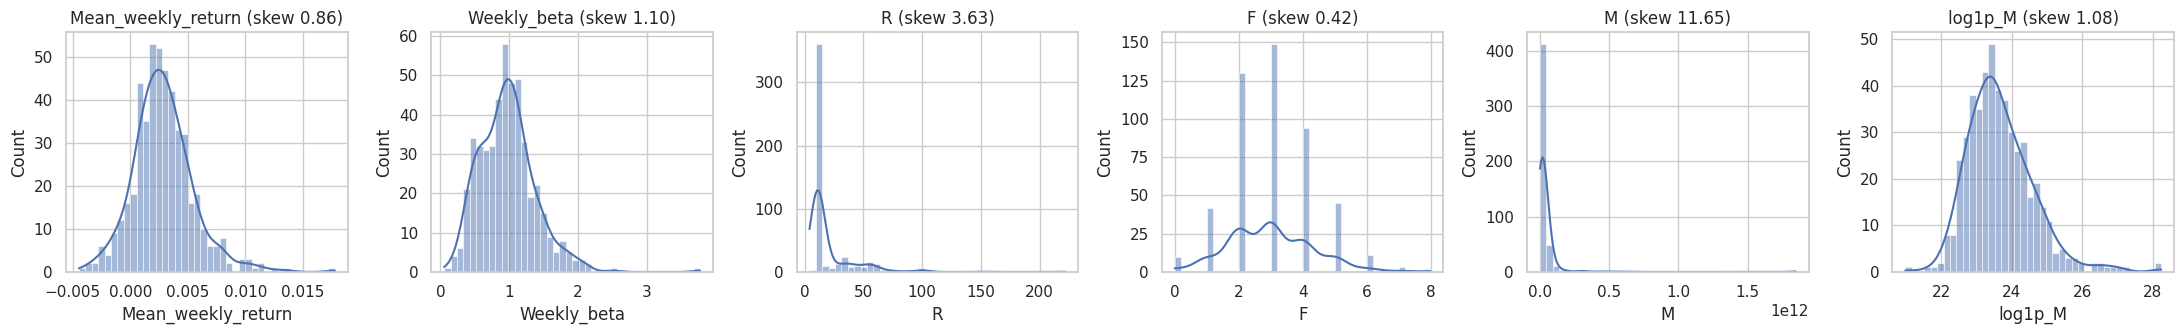

In [13]:
# 2.1 Matrices, skew and outliers
feat = features.loc[common].copy()
feat['log1p_M'] = np.log1p(feat['M'])
RR, RFM = ['Mean_weekly_return', 'Weekly_beta'], ['R', 'F', 'log1p_M']

cols = RR + ['R', 'F', 'M', 'log1p_M']
z = (feat[cols] - feat[cols].mean()) / feat[cols].std()
diag = pd.DataFrame({'skew': feat[cols].apply(skew), '|z| > 3': (z.abs() > 3).sum()})
display(diag.round(3))

X_rr = StandardScaler().fit_transform(feat[RR])
X_rfm = StandardScaler().fit_transform(feat[RFM])

fig, ax = plt.subplots(1, 6, figsize=(22, 3.5))
for a, c in zip(ax, RR + ['R', 'F', 'M', 'log1p_M']):
    sns.histplot(data=feat, x=c, bins=40, kde=True, ax=a); a.set_title(f'{c} (skew {skew(feat[c]):.2f})')
plt.tight_layout(); plt.savefig(f'{FIGS}/distributions.png', dpi=150); plt.show()

## 2.2 and 2.3 Choosing k (2 to 8)
Rule for all four models: highest silhouette where the smallest cluster has at least 3% of shares. Override in `K_OVERRIDE` if profiles support a different k.

In [14]:
# Helper: silhouette, inertia and sizes for k = 2..8
def evaluate(X, method):
    out = []
    for k in range(2, 9):
        if method == 'ward':
            lab, inertia = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X), np.nan
        else:
            km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
            lab, inertia = km.labels_, km.inertia_
        sizes = np.bincount(lab)
        out.append({'k': k, 'silhouette': silhouette_score(X, lab), 'inertia': inertia,
                    'min_size': sizes.min(), 'sizes': sorted(sizes, reverse=True)})
    return pd.DataFrame(out).set_index('k')

def pick_k(tab):
    ok = tab[tab['min_size'] >= 0.03 * len(feat)]
    return int((ok if len(ok) else tab)['silhouette'].idxmax())

K_OVERRIDE = {}

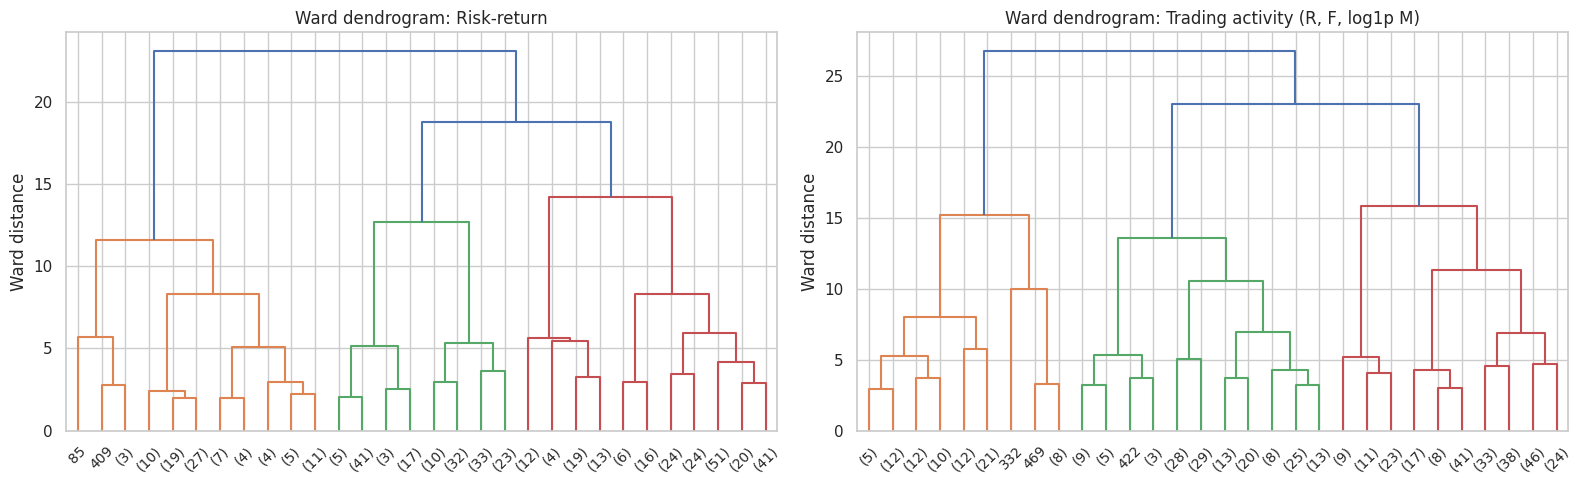

In [15]:
# 2.2 Ward dendrograms (one per matrix)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a, X, title in [(ax[0], X_rr, 'Risk-return'), (ax[1], X_rfm, 'Trading activity (R, F, log1p M)')]:
    dendrogram(linkage(X, method='ward', metric='euclidean'), truncate_mode='lastp', p=30, ax=a)
    a.set_title(f'Ward dendrogram: {title}'); a.set_ylabel('Ward distance')
plt.tight_layout(); plt.savefig(f'{FIGS}/dendrograms.png', dpi=150); plt.show()

RR_Ward


,silhouette,inertia,min_size,sizes
k,,,,
2,0.339,NaN,92,"[394, 92]"
3,0.274,NaN,92,"[230, 164, 92]"
4,0.282,NaN,48,"[182, 164, 92, 48]"
5,0.304,NaN,48,"[182, 98, 92, 66, 48]"
6,0.320,NaN,5,"[182, 98, 87, 66, 48, 5]"
7,0.324,NaN,5,"[160, 98, 87, 66, 48, 22, 5]"
8,0.321,NaN,5,"[160, 98, 66, 56, 48, 31, 22, 5]"


RFM_Ward


,silhouette,inertia,min_size,sizes
k,,,,
2,0.368,NaN,82,"[404, 82]"
3,0.304,NaN,82,"[250, 154, 82]"
4,0.289,NaN,43,"[207, 154, 82, 43]"
5,0.305,NaN,10,"[207, 154, 72, 43, 10]"
6,0.314,NaN,10,"[207, 136, 72, 43, 18, 10]"
7,0.292,NaN,10,"[141, 136, 72, 66, 43, 18, 10]"
8,0.302,NaN,10,"[141, 79, 72, 66, 57, 43, 18, 10]"


RR_KMeans


,silhouette,inertia,min_size,sizes
k,,,,
2,0.387,621.634,143,"[343, 143]"
3,0.329,461.179,119,"[202, 165, 119]"
4,0.327,371.577,40,"[160, 154, 132, 40]"
5,0.341,309.613,27,"[166, 131, 112, 50, 27]"
6,0.335,265.097,5,"[156, 127, 105, 50, 43, 5]"
7,0.328,227.183,5,"[128, 103, 85, 77, 47, 41, 5]"
8,0.354,194.362,5,"[136, 79, 78, 76, 43, 40, 29, 5]"


RFM_KMeans


,silhouette,inertia,min_size,sizes
k,,,,
2,0.423,1066.832,68,"[418, 68]"
3,0.325,796.614,64,"[270, 152, 64]"
4,0.341,609.832,61,"[212, 122, 91, 61]"
5,0.358,514.714,11,"[198, 122, 87, 68, 11]"
6,0.347,437.393,11,"[143, 120, 105, 67, 40, 11]"
7,0.347,386.286,1,"[141, 120, 104, 68, 41, 11, 1]"
8,0.350,342.175,1,"[140, 106, 83, 66, 64, 15, 11, 1]"


Selected k: {'RR_Ward': 2, 'RFM_Ward': 2, 'RR_KMeans': 2, 'RFM_KMeans': 2}


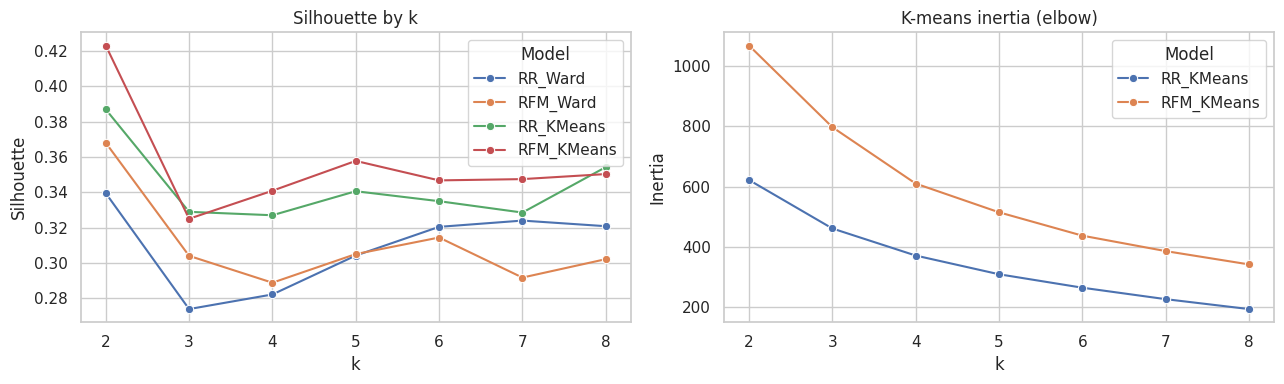

In [16]:
# 2.2 Ward and 2.3 K-means: diagnostics for k = 2..8
tabs = {'RR_Ward': evaluate(X_rr, 'ward'), 'RFM_Ward': evaluate(X_rfm, 'ward'),
        'RR_KMeans': evaluate(X_rr, 'kmeans'), 'RFM_KMeans': evaluate(X_rfm, 'kmeans')}
k_sel = {n: pick_k(t) for n, t in tabs.items()} | K_OVERRIDE
for n, t in tabs.items():
    print(n); display(t.round(3))
print('Selected k:', k_sel)

sil = pd.concat({n: t['silhouette'] for n, t in tabs.items()}, axis=1).reset_index().melt('k', var_name='Model', value_name='Silhouette')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=sil, x='k', y='Silhouette', hue='Model', marker='o', ax=ax[0]); ax[0].set_title('Silhouette by k')
iner = pd.concat({n: tabs[n]['inertia'] for n in ['RR_KMeans', 'RFM_KMeans']}, axis=1).reset_index().melt('k', var_name='Model', value_name='Inertia')
sns.lineplot(data=iner, x='k', y='Inertia', hue='Model', marker='o', ax=ax[1]); ax[1].set_title('K-means inertia (elbow)')
plt.tight_layout(); plt.savefig(f'{FIGS}/k_selection.png', dpi=150); plt.show()

In [17]:
# 2.3 Initialisation check: same groups with 10 other seeds?
for n, X in [('RR_KMeans', X_rr), ('RFM_KMeans', X_rfm)]:
    ref = KMeans(n_clusters=k_sel[n], n_init=50, random_state=SEED).fit_predict(X)
    aris = [adjusted_rand_score(ref, KMeans(n_clusters=k_sel[n], n_init=50, random_state=s).fit_predict(X)) for s in range(1, 11)]
    print(f'{n}: lowest ARI vs seed 42 = {min(aris):.3f}')

RR_KMeans: lowest ARI vs seed 42 = 1.000
RFM_KMeans: lowest ARI vs seed 42 = 1.000


In [18]:
# Four baseline solutions
feat['RR_Ward'] = AgglomerativeClustering(n_clusters=k_sel['RR_Ward'], linkage='ward').fit_predict(X_rr)
feat['RFM_Ward'] = AgglomerativeClustering(n_clusters=k_sel['RFM_Ward'], linkage='ward').fit_predict(X_rfm)
feat['RR_KMeans'] = KMeans(n_clusters=k_sel['RR_KMeans'], n_init=50, random_state=SEED).fit_predict(X_rr)
feat['RFM_KMeans'] = KMeans(n_clusters=k_sel['RFM_KMeans'], n_init=50, random_state=SEED).fit_predict(X_rfm)
SOLS = ['RR_Ward', 'RR_KMeans', 'RFM_Ward', 'RFM_KMeans']

## 2.4 Profiles (original units) and algorithm comparison

In [19]:
# 2.4 Profiles in original units
def profile(sol):
    return feat.groupby(sol).agg(Shares=('F', 'size'),
                                 Mean_return_pct=('Mean_weekly_return', lambda s: s.mean() * 100),
                                 Mean_beta=('Weekly_beta', 'mean'),
                                 Median_R_days=('R', 'median'), Mean_F_days=('F', 'mean'),
                                 Median_M_USDbn=('M', lambda s: s.median() / 1e9))
profiles = {s: profile(s) for s in SOLS}
for s, p in profiles.items():
    print(s); display(p.round(3))

RR_Ward


,Shares,Mean_return_pct,Mean_beta,Median_R_days,Mean_F_days,Median_M_USDbn
RR_Ward,,,,,,
0,394,0.205,0.898,11.0,2.942,15.325
1,92,0.632,1.298,11.0,3.196,24.184


RR_KMeans


,Shares,Mean_return_pct,Mean_beta,Median_R_days,Mean_F_days,Median_M_USDbn
RR_KMeans,,,,,,
0,143,0.533,1.350,11.0,3.147,25.524
1,343,0.183,0.817,11.0,2.924,14.206


RFM_Ward


,Shares,Mean_return_pct,Mean_beta,Median_R_days,Mean_F_days,Median_M_USDbn
RFM_Ward,,,,,,
0,404,0.286,0.967,11.0,3.171,16.047
1,82,0.286,1.009,54.5,2.098,17.849


RFM_KMeans


,Shares,Mean_return_pct,Mean_beta,Median_R_days,Mean_F_days,Median_M_USDbn
RFM_KMeans,,,,,,
0,418,0.283,0.972,11.0,3.187,15.57
1,68,0.302,0.982,55.0,1.779,22.25


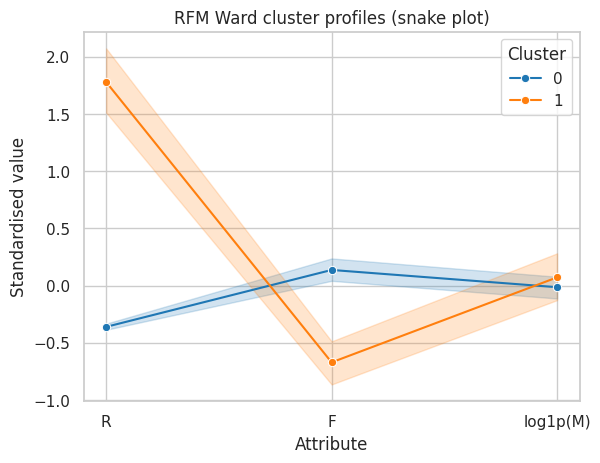

In [20]:
# 2.4 Snake plot (as in the RFM K-means tutorial): standardised RFM profile of each Ward cluster
snake = pd.DataFrame(X_rfm, columns=['R', 'F', 'log1p(M)'], index=feat.index).assign(Cluster=feat['RFM_Ward']).rename_axis('Ticker')
snake = snake.reset_index().melt(id_vars=['Ticker', 'Cluster'], var_name='Attribute', value_name='Standardised value')
sns.lineplot(data=snake, x='Attribute', y='Standardised value', hue='Cluster', palette='tab10', marker='o')
plt.title('RFM Ward cluster profiles (snake plot)'); plt.savefig(f'{FIGS}/rfm_snake_plot.png', dpi=150, bbox_inches='tight'); plt.show()

,PC1,PC2
R,0.711,0.023
F,-0.650,0.402
log1p_M,0.268,0.915


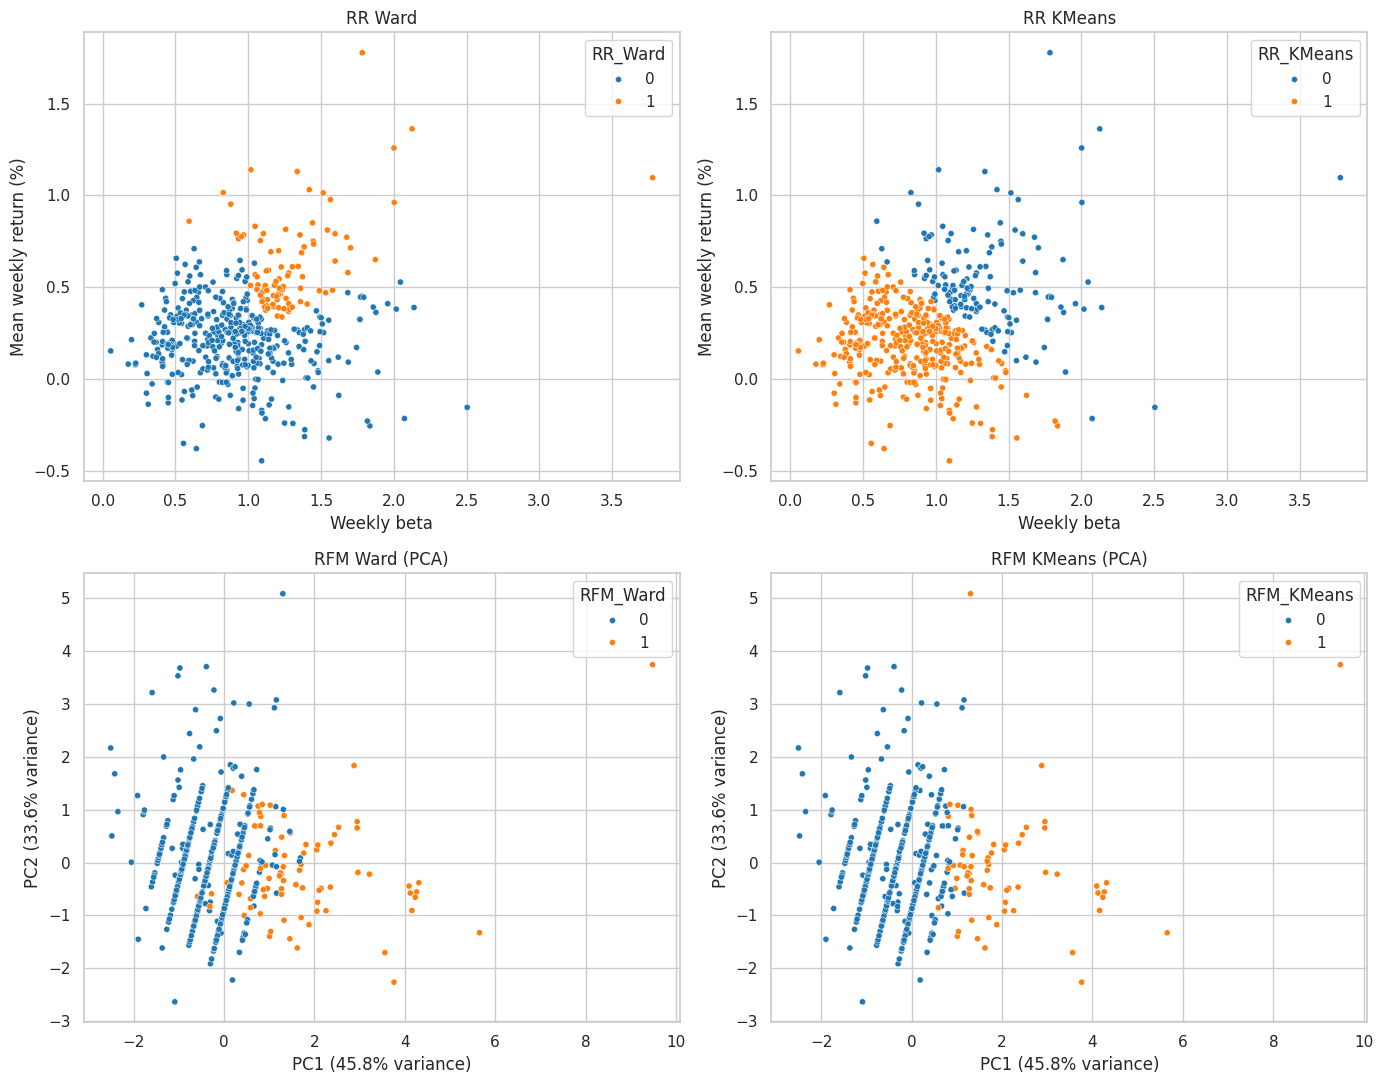

In [21]:
# 2.4 Labelled 2D plots: risk-return in original units; RFM projected with PCA (3 features -> 2)
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
feat[['PC1', 'PC2']] = pca.transform(X_rfm)
ev = pca.explained_variance_ratio_ * 100
display(pd.DataFrame(pca.components_.T, index=RFM, columns=['PC1', 'PC2']).round(3))

fig, ax = plt.subplots(2, 2, figsize=(14, 11))
for a, s in zip(ax[0], ['RR_Ward', 'RR_KMeans']):
    sns.scatterplot(data=feat, x='Weekly_beta', y=feat['Mean_weekly_return'] * 100, hue=s, palette='tab10', s=20, ax=a)
    a.set(xlabel='Weekly beta', ylabel='Mean weekly return (%)', title=s.replace('_', ' '))
for a, s in zip(ax[1], ['RFM_Ward', 'RFM_KMeans']):
    sns.scatterplot(data=feat, x='PC1', y='PC2', hue=s, palette='tab10', s=20, ax=a)
    a.set(xlabel=f'PC1 ({ev[0]:.1f}% variance)', ylabel=f'PC2 ({ev[1]:.1f}% variance)', title=s.replace('_', ' ') + ' (PCA)')
plt.tight_layout(); plt.savefig(f'{FIGS}/cluster_scatter.png', dpi=150); plt.show()

In [22]:
# 2.4 Ward vs K-means on the same shares
ari_algo = {}
for m in ['RR', 'RFM']:
    ari_algo[m] = adjusted_rand_score(feat[f'{m}_Ward'], feat[f'{m}_KMeans'])
    print(f'{m}: ARI Ward vs K-means = {ari_algo[m]:.3f}')
    display(pd.crosstab(feat[f'{m}_Ward'], feat[f'{m}_KMeans']))

RR: ARI Ward vs K-means = 0.598


RR_KMeans,0,1
RR_Ward,,
0,51,343
1,92,0


RFM: ARI Ward vs K-means = 0.700


RFM_KMeans,0,1
RFM_Ward,,
0,396,8
1,22,60


## 2.5.1 Correlations among R, F and log1p(M)

,R,F,log1p_M
R,1.000,-0.346,0.152
F,-0.346,1.000,0.013
log1p_M,0.152,0.013,1.000


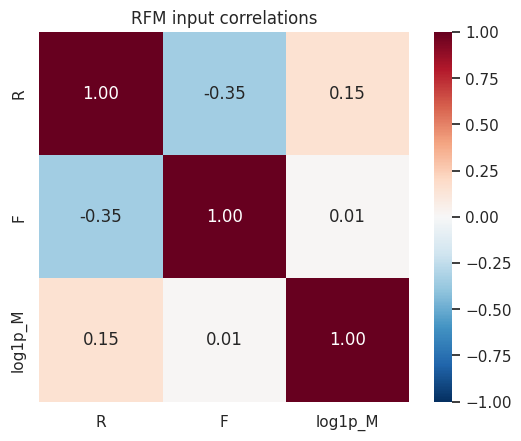

In [23]:
# 2.5.1 Correlation table and heatmap
corr = feat[RFM].corr()
display(corr.round(3))
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='RdBu_r', square=True)
plt.title('RFM input correlations'); plt.savefig(f'{FIGS}/rfm_correlation.png', dpi=150, bbox_inches='tight'); plt.show()

## 2.5.2 Removal of Monetary (same shares, same k, R and F re-standardised)

In [24]:
# 2.5.2 Ward on R and F only
X_rf = StandardScaler().fit_transform(feat[['R', 'F']])
feat['RF_Ward'] = AgglomerativeClustering(n_clusters=k_sel['RFM_Ward'], linkage='ward').fit_predict(X_rf)
ari_rf = adjusted_rand_score(feat['RFM_Ward'], feat['RF_Ward'])
print(f'ARI (R,F,M vs R,F only): {ari_rf:.3f}')
display(pd.crosstab(feat['RFM_Ward'], feat['RF_Ward'], margins=True))

tv = pd.concat({'With M': feat.groupby('RFM_Ward')['M'].median(), 'Without M': feat.groupby('RF_Ward')['M'].median()}) / 1e9
print('Median traded value by cluster (USD bn):'); display(tv.round(2).to_frame('Median M'))
display(profile('RF_Ward').round(3))

ARI (R,F,M vs R,F only): 0.873


RF_Ward,0,1,All
RFM_Ward,,,
0,394,10,404
1,3,79,82
All,397,89,486


Median traded value by cluster (USD bn):


Median M
          RFM_Ward          
With M    0            16.05
          1            17.85
Without M 0            15.46
          1            20.85

,Shares,Mean_return_pct,Mean_beta,Median_R_days,Mean_F_days,Median_M_USDbn
RF_Ward,,,,,,
0,397,0.283,0.967,11.0,3.209,15.464
1,89,0.297,1.002,54.0,2.011,20.848


## Task 3 support: sector composition

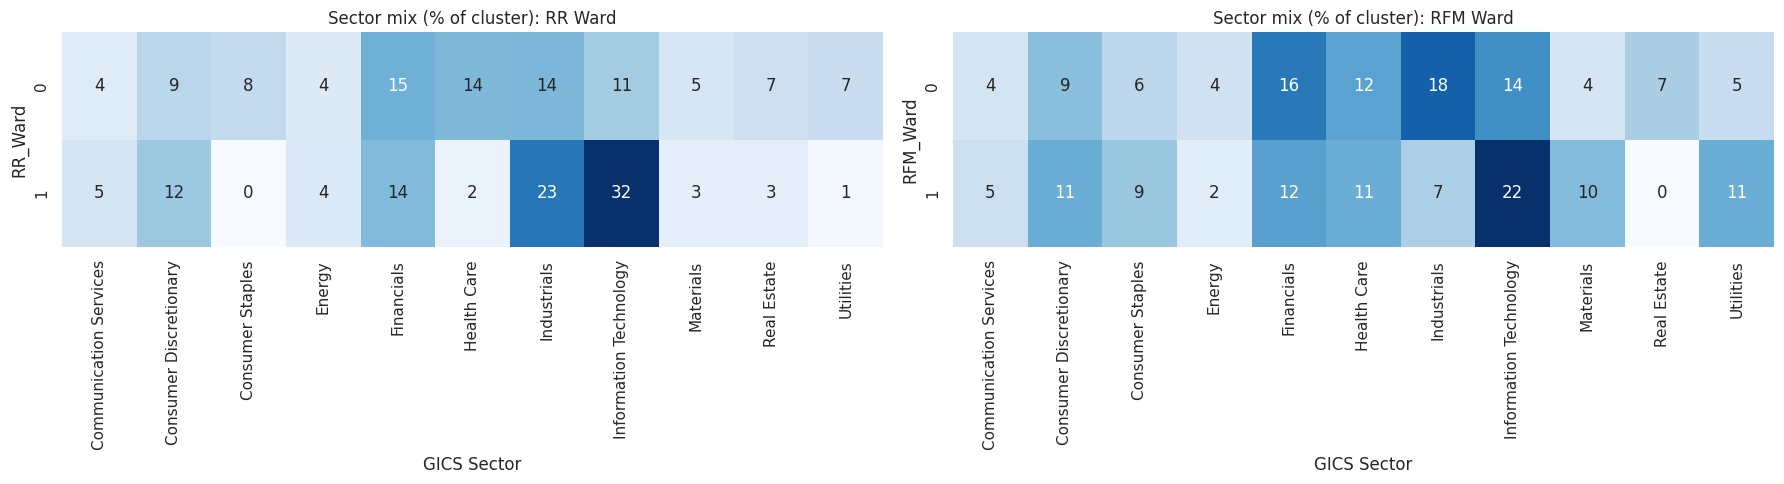

Overlap of risk-return and RFM groups (ARI): 0.029


In [25]:
# 3.2.1 Sector mix (% of each cluster) for the selected Ward solutions
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for a, s in zip(ax, ['RR_Ward', 'RFM_Ward']):
    mix = pd.crosstab(feat[s], feat['GICS Sector'], normalize='index') * 100
    sns.heatmap(mix, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=a)
    a.set_title(f'Sector mix (% of cluster): {s.replace("_", " ")}')
plt.tight_layout(); plt.savefig(f'{FIGS}/sector_mix.png', dpi=150); plt.show()

ari_cross = adjusted_rand_score(feat['RR_Ward'], feat['RFM_Ward'])
print(f'Overlap of risk-return and RFM groups (ARI): {ari_cross:.3f}')

In [26]:
# Save the feature table with all cluster assignments, plus key results for the report
feat.drop(columns=['PC1', 'PC2']).to_csv(f'{DATA}/feature_table_with_clusters.csv')
json.dump({'meta': meta, 'inclusion': inclusion.to_dict(), 'weeks': len(wret), 'k': k_sel,
           'silhouette': {n: float(tabs[n].loc[k_sel[n], 'silhouette']) for n in tabs},
           'ari_ward_vs_kmeans': ari_algo, 'ari_rfm_vs_rf': ari_rf, 'ari_rr_vs_rfm': ari_cross,
           'pca_variance_pct': ev.tolist(), 'rfm_corr': corr.round(4).to_dict(),
           'summary': summary.round(6).to_dict(), 'profiles': {s: p.round(4).to_dict() for s, p in profiles.items()}},
          open(f'{DATA}/results_summary.json', 'w'), indent=2, default=str)
print('Saved feature_table_with_clusters.csv and results_summary.json')

Saved feature_table_with_clusters.csv and results_summary.json


In [27]:
# Submission checks (from the tutorial solution)
checks = {
    'Period is 2021-01-01 to 2025-01-01': (START, END) == ('2021-01-01', '2025-01-01'),
    'Benchmark present': BENCH in adj.columns,
    'No missing prices in retained shares': not daily.isna().any().any(),
    'Same week labels for shares and benchmark': weekly_returns.index.equals(market_weekly_returns.index),
    'Every share has a full 60-session window': bool(baseline.loc[window].notna().all().all()),
    'Common share set used everywhere': feat[SOLS + ['RF_Ward']].notna().all().all() and len(feat) == len(common),
}
display(pd.Series(checks, name='Passed'))
assert all(checks.values())

,Passed
Period is 2021-01-01 to 2025-01-01,True
Benchmark present,True
No missing prices in retained shares,True
Same week labels for shares and benchmark,True
Every share has a full 60-session window,True
Common share set used everywhere,True


In [28]:
from google.colab import files; files.download('data/results_summary.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
import shutil, glob, os
from google.colab import files

os.makedirs('results_export', exist_ok=True)
for f in glob.glob('data/*.csv') + glob.glob('data/*.json') + glob.glob('figures/*.png'):
    shutil.copy(f, 'results_export')

shutil.make_archive('cwk1_results', 'zip', 'results_export')
files.download('cwk1_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# 1. Apple worked example: high-volume days in the 60-session window
ex = 'AAPL'
wk = pd.DataFrame({'Volume': vol_d.loc[window, ex],
                   'Prior 20-day mean': baseline.loc[window, ex],
                   '2x threshold': 2 * baseline.loc[window, ex],
                   'High volume': event.loc[window, ex]})
print(wk[wk['High volume']].round(0))

# 2. Split check: any >50% daily move not on a split day
print('Unexplained >50% moves:', big.stack().loc[lambda x: x].index.tolist())

# 3. Beta vs regression slope
print('Max beta vs OLS difference:', float((beta_df['Beta'] - ols).abs().max()))

# 4. K-means seed stability
for n, X in [('RR_KMeans', X_rr), ('RFM_KMeans', X_rfm)]:
    ref = KMeans(n_clusters=k_sel[n], n_init=50, random_state=SEED).fit_predict(X)
    print(n, 'lowest ARI vs seed 42:', min(adjusted_rand_score(ref, KMeans(n_clusters=k_sel[n], n_init=50, random_state=s).fit_predict(X)) for s in range(1, 11)))

               Volume  Prior 20-day mean  2x threshold  High volume
Date                                                               
2024-11-25   90152800         43820740.0    87641480.0         True
2024-12-20  147495300         45004605.0    90009210.0         True
Unexplained >50% moves: [(Timestamp('2023-06-08 00:00:00'), 'CVNA'), (Timestamp('2024-04-11 00:00:00'), 'GL'), (Timestamp('2024-11-15 00:00:00'), 'BE')]
Max beta vs OLS difference: 2.220446049250313e-15
RR_KMeans lowest ARI vs seed 42: 1.0
RFM_KMeans lowest ARI vs seed 42: 1.0
